In [58]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/ai-vs-human-text/AI_Human.csv


In [82]:
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
import scikitplot as skplt
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score,precision_recall_fscore_support

In [60]:
data = pd.read_csv('/kaggle/input/ai-vs-human-text/AI_Human.csv')

In [61]:
data

,text,generated
0,Cars. Cars have been around since they became ...,0.0
1,Transportation is a large necessity in most co...,0.0
2,"""America's love affair with it's vehicles seem...",0.0
3,How often do you ride in a car? Do you drive a...,0.0
4,Cars are a wonderful thing. They are perhaps o...,0.0
...,...,...
487230,Tie Face on Mars is really just a big misunder...,0.0
487231,The whole purpose of democracy is to create a ...,0.0
487232,I firmly believe that governments worldwide sh...,1.0
487233,I DFN't agree with this decision because a LFT...,0.0


In [62]:
# Count total entries
total_entries = len(data['generated'])

# Count AI-generated text
ai_generated_count = data['generated'].eq(1.0).sum()

# Count human-generated text
human_generated_count = data['generated'].eq(0.0).sum()

# Print the results
print("Total :", total_entries)
print("Total text by AI :", ai_generated_count)
print("Total text by Human :", human_generated_count)


Total : 487235
Total text by AI : 181438
Total text by Human : 305797


In [63]:
data['generated'].value_counts()

generated
0.0    305797
1.0    181438
Name: count, dtype: int64

In [64]:
percentage_ai = (text_by_ai / total_text) * 100
percentage_human = (text_by_human / total_text) * 100

print("Percentage of text by AI:", round(percentage_ai, 2), "%")
print("Percentage of text by Human:", round(percentage_human, 2), "%")


Percentage of text by AI: 37.24 %
Percentage of text by Human: 62.76 %


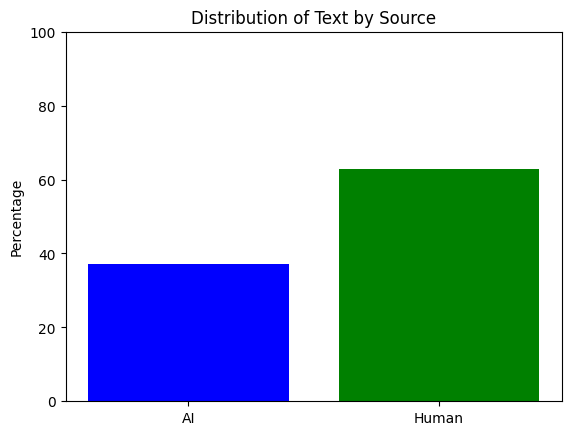

In [65]:
import matplotlib.pyplot as plt

categories = ['AI', 'Human']
percentages = [percentage_ai, percentage_human]

# Create bar chart
plt.bar(categories, percentages, color=['blue', 'green'])
plt.ylabel('Percentage')
plt.title('Distribution of Text by Source')
plt.ylim(0, 100)
plt.show()


In [66]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 487235 entries, 0 to 487234
Data columns (total 2 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   text       487235 non-null  object 
 1   generated  487235 non-null  float64
dtypes: float64(1), object(1)
memory usage: 7.4+ MB


In [67]:
print("Summary Statistics for 'generated' column:")
print(data['generated'].describe())

Summary Statistics for 'generated' column:
count    487235.000000
mean          0.372383
std           0.483440
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max           1.000000
Name: generated, dtype: float64


/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


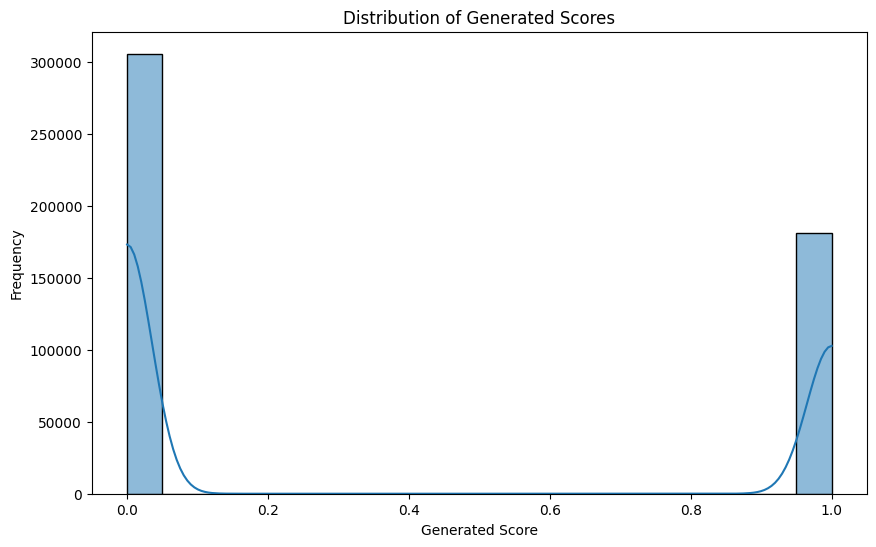

In [68]:
plt.figure(figsize=(10, 6))
sns.histplot(data['generated'], bins=20, kde=True)
plt.title("Distribution of Generated Scores")
plt.xlabel("Generated Score")
plt.ylabel("Frequency")
plt.show()

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


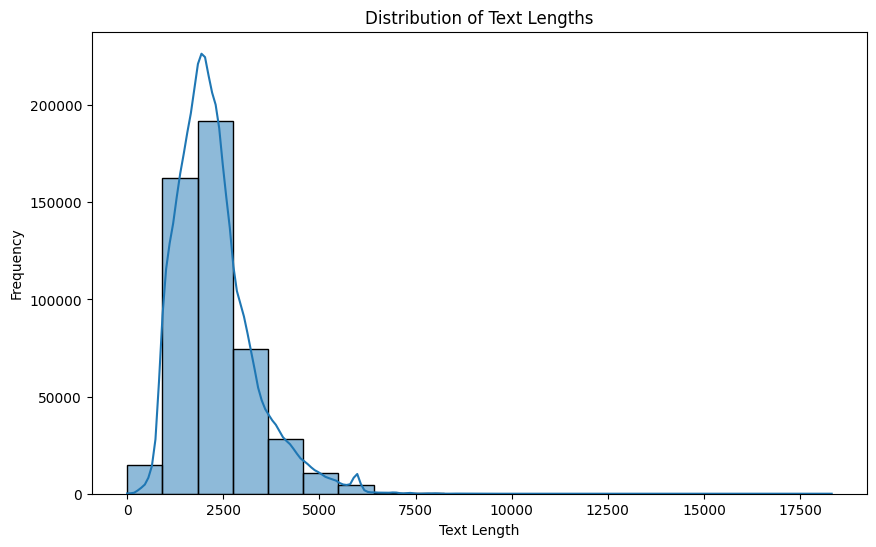

In [69]:
data['text_length'] = data['text'].apply(len)
plt.figure(figsize=(10, 6))
sns.histplot(data['text_length'], bins=20, kde=True)
plt.title("Distribution of Text Lengths")
plt.xlabel("Text Length")
plt.ylabel("Frequency")
plt.show()

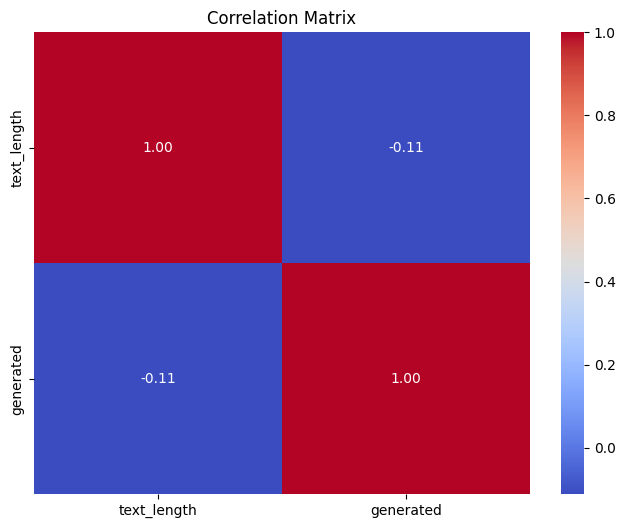

In [70]:
correlation = data[['text_length', 'generated']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [74]:


# Preprocessing: Split data into features (X) and target labels (y)
X = data['text']
y = data['generated']  # Assuming 'generated' column contains sentiment labels (1 for AI, 0 for Human)



In [75]:
tfidf_vectorizer = TfidfVectorizer(max_features=10000)
X_tfidf = tfidf_vectorizer.fit_transform(X)

In [76]:

X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.2, stratify = y, 
                                                    random_state=42)

In [79]:
lr_classifier = LogisticRegression()
lr_classifier.fit(X_train, y_train)

/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [80]:
y_pred = lr_classifier.predict(X_test)
lr_accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", lr_accuracy)

Accuracy: 0.994684289921701


In [83]:
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted')
print('Precision:', precision)
print('Recall:', recall)
print('F1 Score:', f1)

Precision: 0.9946888135777503
Recall: 0.994684289921701
F1 Score: 0.9946809196803736


In [84]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

report = classification_report(y_test, y_pred)
print("Classification Report:\n", report)

conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", conf_matrix)

Accuracy: 0.994684289921701
Classification Report:
               precision    recall  f1-score   support

         0.0       0.99      1.00      1.00     61159
         1.0       1.00      0.99      0.99     36288

    accuracy                           0.99     97447
   macro avg       0.99      0.99      0.99     97447
weighted avg       0.99      0.99      0.99     97447

Confusion Matrix:
 [[61012   147]
 [  371 35917]]


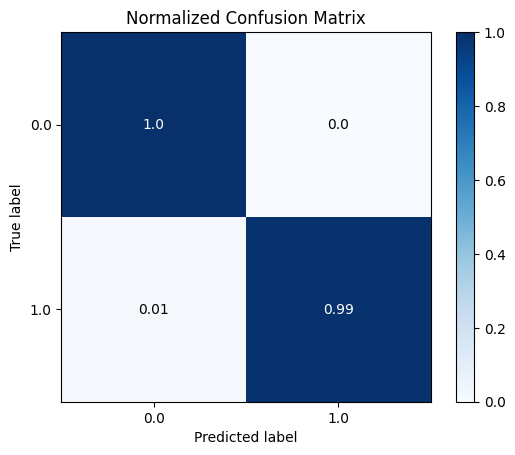

In [85]:
skplt.metrics.plot_confusion_matrix(y_test, y_pred, normalize=True)
plt.show()